# 04 - San Diego: corners
1. Corners: takers, delivery, target area
2. Corner targets

## Setup

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from mplsoccer import VerticalPitch

pd.set_option("display.max_columns", 50)

In [2]:
PROCESSED_FOLDER = Path("../../data/processed")
FIGURES_FOLDER = Path("../../figures")

# colours
SD_COLOR = "#2a78d6"          # San Diego = blue
OPPONENT_COLOR = "#eb6834"    # opponents = orange
BACKGROUND = "#fcfcfb"
LINE_COLOR = "#9a9890"
TEXT_COLOR = "#0b0b0b"
TEXT_MUTED = "#52514e"

SHORT_NAMES = {
    "Hirving Rodrigo Lozano Bahena": "Chucky Lozano",
    "Anders Laustrup Dreyer": "Anders Dreyer",
    "Onni Johannes Simonpoika Valakari": "Onni Valakari",
    "Tomas Ángel Gutiérrez": "Tomás Ángel",
    "Alexander Cole Mighten": "Alex Mighten",
    "Jeppe Theis Tverskov": "Jeppe Tverskov",
    "Marcus Højriis Ingvartsen": "Marcus Ingvartsen",
    "Christopher Donald McVey": "Chris McVey",
    "Patrick James Coleman McNair": "Paddy McNair",
    "Aníbal Cesis Godoy": "Aníbal Godoy",
    "Luca Dylan Bombino": "Luca Bombino",
    "Oscar Anthony Verhoeven": "Oscar Verhoeven",
}

In [3]:
events = pd.read_parquet(PROCESSED_FOLDER / "sb_events.parquet")

sd_match_events = events[events["focus_team"] == "San Diego"]
is_sd_action = sd_match_events["team"] == "San Diego FC"
sd_own_events = sd_match_events[is_sd_action].copy()
opponent_events_vs_sd = sd_match_events[~is_sd_action]

# short names
sd_own_events["player_name"] = sd_own_events["player"].replace(SHORT_NAMES)

number_of_matches = sd_match_events["match_id"].nunique()
print("San Diego matches:", number_of_matches)

San Diego matches: 24


## 1 - Corners

In [4]:
is_corner = (sd_own_events["type"] == "Pass") & (sd_own_events["pass_type"] == "Corner")
sd_corners = sd_own_events[is_corner].copy()
print("Corners:", len(sd_corners), "| per game:", round(len(sd_corners) / number_of_matches, 1))

corner_columns = ["player_name", "x", "y", "end_x", "end_y", "pass_length",
                  "pass_body_part", "pass_technique", "pass_outcome"]
sd_corners[corner_columns].head()

Corners: 124 | per game: 5.2


,player_name,x,y,end_x,end_y,pass_length,pass_body_part,pass_technique,pass_outcome
4030,Chucky Lozano,120.0,0.1,115.4,47.6,47.72,Right Foot,Inswinging,Incomplete
4496,Chucky Lozano,120.0,0.1,117.1,37.1,37.11,Right Foot,Inswinging,Incomplete
4658,Chucky Lozano,120.0,0.1,112.4,40.8,41.40,Right Foot,Inswinging,Incomplete
12174,Anders Dreyer,120.0,80.0,115.1,46.9,33.46,Left Foot,Inswinging,NaN
12218,Anders Dreyer,120.0,0.1,117.3,33.6,33.61,Left Foot,Outswinging,Incomplete


Corner side: y near 0 = left, near 80 = right

In [5]:
sd_corners["corner_side"] = np.where(sd_corners["y"] < 40, "Left corner", "Right corner")

# who takes them, from which side, with which foot
takers = sd_corners.groupby(["player_name", "corner_side", "pass_body_part"]).size()
takers = takers.reset_index(name="corners")
takers = takers.sort_values("corners", ascending=False)
takers.head(8)

,player_name,corner_side,pass_body_part,corners
1,Anders Dreyer,Right corner,Left Foot,47
3,Chucky Lozano,Left corner,Right Foot,33
0,Anders Dreyer,Left corner,Left Foot,17
6,Luca de la Torre,Left corner,Right Foot,13
9,Milan Iloski,Left corner,Right Foot,8
4,Chucky Lozano,Right corner,Right Foot,2
2,Anders Dreyer,Right corner,Right Foot,1
5,Luca Bombino,Left corner,Right Foot,1


In [6]:
# empty = usually a short corner
sd_corners["pass_technique"] = sd_corners["pass_technique"].fillna("None (mostly short)")
sd_corners["pass_technique"].value_counts()

pass_technique
Inswinging             73
None (mostly short)    34
Outswinging            16
Straight                1
Name: count, dtype: int64

In [7]:
# technique by taker
pd.crosstab(sd_corners["player_name"], sd_corners["pass_technique"])

pass_technique,Inswinging,None (mostly short),Outswinging,Straight
player_name,,,,
Anders Dreyer,34,16,14,1
Chucky Lozano,24,9,2,0
Luca Bombino,0,1,0,0
Luca de la Torre,8,6,0,0
Milan Iloski,7,2,0,0


### Target area
Posts at y = 36 and 44, measured from the corner side:
- Near post: < 36
- Central: 36–44
- Far post: > 44
- Short: pass under 15 yards
- Edge of box: x < 102

In [8]:
def corner_zone(row):
    if row["pass_length"] < 15:
        return "Short"
    if row["end_x"] < 102:
        return "Edge of box"

    # distance from the corner's side
    if row["corner_side"] == "Left corner":
        distance_from_corner_side = row["end_y"]
    else:
        distance_from_corner_side = 80 - row["end_y"]

    if distance_from_corner_side < 36:
        return "Near post"
    elif distance_from_corner_side <= 44:
        return "Central"
    else:
        return "Far post"

sd_corners["zone"] = sd_corners.apply(corner_zone, axis=1)
zone_share = sd_corners["zone"].value_counts(normalize=True)
zone_share.round(2)

zone
Near post      0.43
Central        0.31
Short          0.14
Far post       0.10
Edge of box    0.02
Name: proportion, dtype: float64

43% near post, 31% central, 10% far post, 14% short.

### Corner delivery map
All corners shown from the left (right-side corners mirrored).

In [9]:
long_corners = sd_corners[sd_corners["zone"] != "Short"].copy()

is_right_corner = long_corners["corner_side"] == "Right corner"
long_corners["plot_y"] = np.where(is_right_corner, 80 - long_corners["end_y"], long_corners["end_y"])

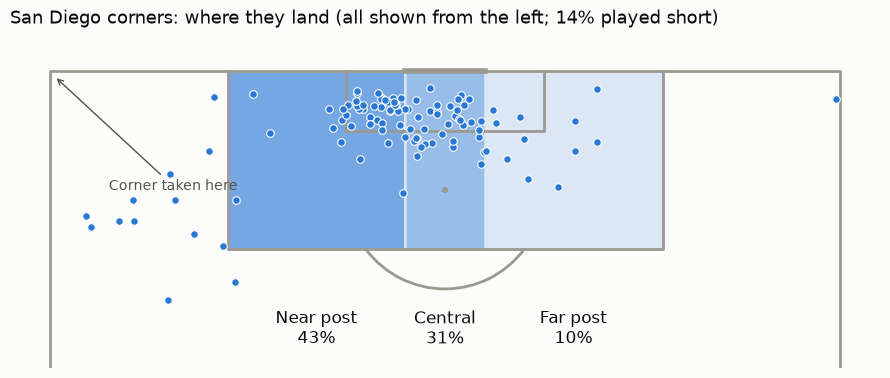

In [10]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True, pad_bottom=-30,
                      pitch_color=BACKGROUND, line_color=LINE_COLOR, line_zorder=2)
fig, ax = pitch.draw(figsize=(9, 7))
fig.set_facecolor(BACKGROUND)

# (y from, y to, zone)
zone_bands = [(18, 36, "Near post"), (36, 44, "Central"), (44, 62, "Far post")]

for y_from, y_to, zone in zone_bands:
    share = zone_share.get(zone, 0)
    band = Rectangle((y_from, 102), y_to - y_from, 18, facecolor=SD_COLOR, alpha=share * 1.5,
                     edgecolor=BACKGROUND, linewidth=2, zorder=1)
    ax.add_patch(band)
    ax.text((y_from + y_to) / 2, 96, f"{zone}\n{share:.0%}", ha="center", va="top", fontsize=12, color=TEXT_COLOR)

# landing spots
pitch.scatter(long_corners["end_x"], long_corners["plot_y"], s=30, color=SD_COLOR,
              edgecolor=BACKGROUND, linewidth=0.8, ax=ax, zorder=3)

# corner spot
ax.annotate("Corner taken here", xy=(0.5, 119.5), xytext=(6, 108), fontsize=10, color=TEXT_MUTED,
            arrowprops=dict(arrowstyle="->", color=TEXT_MUTED))

short_share = zone_share.get("Short", 0)
ax.set_title(f"San Diego corners: where they land (all shown from the left; {short_share:.0%} played short)",
             fontsize=13, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex1_sd_corner_delivery.png", dpi=200, bbox_inches="tight")
plt.show()

## 2 - Corner targets
Shots from possessions that started with a corner.

In [11]:
sd_shots = sd_own_events[sd_own_events["type"] == "Shot"]
corner_shots = sd_shots[sd_shots["play_pattern"] == "From Corner"].copy()
corner_shots["is_goal"] = corner_shots["shot_outcome"] == "Goal"
corner_shots["is_header"] = corner_shots["shot_body_part"] == "Head"

print("Shots from corners:", len(corner_shots))
print("Goals from corners:", corner_shots["is_goal"].sum())
print("xG from corners:", round(corner_shots["shot_statsbomb_xg"].sum(), 2))

Shots from corners: 49
Goals from corners: 4
xG from corners: 4.11


In [12]:
corner_targets = corner_shots.groupby("player_name").agg(
    shots=("is_goal", "size"),
    headers=("is_header", "sum"),
    goals=("is_goal", "sum"),
    xG=("shot_statsbomb_xg", "sum"),
)
corner_targets.sort_values("xG", ascending=False).head(6).round(2)

,shots,headers,goals,xG
player_name,,,,
Jeppe Tverskov,11,8,1,1.01
Chris McVey,4,4,1,0.95
Paddy McNair,4,2,0,0.41
Marcus Ingvartsen,4,2,0,0.40
Onni Valakari,2,2,1,0.29
Aníbal Godoy,3,0,0,0.22


Tverskov is the main target: 11 shots from corners, 8 of them headers.